# Heart Disease Risk — Part 1: Data Cleaning and Exploratory Data Analysis

**Course:** CS 746 PDS &nbsp;|&nbsp; **Student:** Pranu Manandhar

**Research question:** Which clinical and demographic factors are most closely linked to the presence of heart
disease, and can simple statistical and machine learning methods predict whether a patient has heart disease?

This notebook covers the first two stages of the project:

1. **Data cleaning** – loading, checking data types, finding missing values (including values hidden as `0`),
   removing duplicates, checking outliers, and creating the binary target.
2. **Exploratory data analysis (EDA)** – class balance, distributions, boxplots by disease status,
   a correlation heatmap, and disease prevalence by age group, sex and categorical features.

Statistical testing (t-tests, chi-square) and modelling (logistic regression) come in the next notebook.

**Dataset:** UCI Heart Disease (Janosi et al., 1988), Kaggle version by R. Karim Sony
(`data/heart_disease_uci.csv`, 920 patients from four hospitals, 16 columns).

**Reproducibility:** run all cells from top to bottom. Figures are saved to `figures/` and the cleaned
dataset to `data/cleveland_clean.csv`.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# Paths (the notebook lives in notebooks/, data and figures sit one level up)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = ROOT / "data" / "heart_disease_uci.csv"
DATA_CLEAN = ROOT / "data" / "cleveland_clean.csv"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42

# Consistent figure style used for every chart in the project
NO_DISEASE, DISEASE = "#2a78d6", "#eb6834"      # target colours (blue / orange)
FEMALE, MALE = "#1baf7a", "#6250d6"             # sex colours (aqua / violet)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
TARGET_PALETTE = {"No disease": NO_DISEASE, "Disease": DISEASE}

def save(fig, name):
    """Save a figure to figures/ as PNG."""
    fig.savefig(FIG_DIR / f"{name}.png")
    print(f"saved figures/{name}.png")

print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.0.5 | seaborn 0.13.2


## 1. Load the raw data and inspect it

In [2]:
raw = pd.read_csv(DATA_RAW)
print("Shape:", raw.shape)
raw.head()

Shape: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


In [4]:
# Patients per hospital (the 'dataset' column records the source site)
raw["dataset"].value_counts()

dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

### Data dictionary

| Column | Meaning | Type |
|---|---|---|
| `age` | Age in years | numeric |
| `sex` | Male / Female | categorical |
| `cp` | Chest pain type (typical angina, atypical angina, non-anginal, asymptomatic) | categorical |
| `trestbps` | Resting blood pressure (mm Hg) | numeric |
| `chol` | Serum cholesterol (mg/dl) | numeric |
| `fbs` | Fasting blood sugar > 120 mg/dl | binary |
| `restecg` | Resting ECG result (normal, ST-T abnormality, LV hypertrophy) | categorical |
| `thalch` | Maximum heart rate achieved | numeric |
| `exang` | Exercise-induced angina | binary |
| `oldpeak` | ST depression induced by exercise relative to rest | numeric |
| `slope` | Slope of the peak exercise ST segment | categorical |
| `ca` | Number of major vessels (0–3) coloured by fluoroscopy | ordinal |
| `thal` | Thallium stress test result (normal, fixed defect, reversible defect) | categorical |
| `num` | Diagnosis: 0 = no disease, 1–4 = increasing severity | target |

## 2. Data cleaning

### 2.1 Missing values – including values hidden as zero
A serum cholesterol of 0 mg/dl or a resting blood pressure of 0 mm Hg is not physiologically possible,
so these zeros are really missing values. We first count them, then convert them to `NaN`.

In [5]:
zero_counts = pd.DataFrame({
    "chol == 0": raw.groupby("dataset")["chol"].apply(lambda s: (s == 0).sum()),
    "trestbps == 0": raw.groupby("dataset")["trestbps"].apply(lambda s: (s == 0).sum()),
})
zero_counts

,chol == 0,trestbps == 0
dataset,,
Cleveland,0,0
Hungary,0,0
Switzerland,123,0
VA Long Beach,49,1


In [6]:
df = raw.copy()
for col in ["chol", "trestbps"]:
    df.loc[df[col] == 0, col] = np.nan

# Missing values per column, per hospital (percent)
features = [c for c in df.columns if c not in ("id", "dataset", "num")]
missing_pct = (df[features].isna().groupby(df["dataset"]).mean() * 100).round(1)
missing_pct

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal
dataset,,,,,,,,,,,,,
Cleveland,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.3,1.6,1.0
Hungary,0.0,0.0,0.0,0.3,7.8,2.7,0.3,0.3,0.3,0.0,64.5,99.0,90.4
Switzerland,0.0,0.0,0.0,1.6,100.0,61.0,0.8,0.8,0.8,4.9,13.8,95.9,42.3
VA Long Beach,0.0,0.0,0.0,28.5,28.0,3.5,0.0,26.5,26.5,28.0,51.0,99.0,83.0


saved figures/fig1_missing_by_site.png


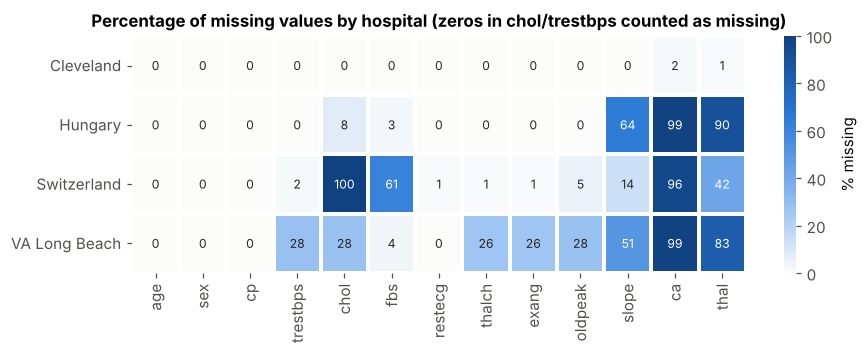

In [7]:
fig, ax = plt.subplots(figsize=(9, 2.8))
seq = LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#86b6ef", "#2a78d6", "#104281"])
sns.heatmap(missing_pct, annot=True, fmt=".0f", cmap=seq, vmin=0, vmax=100, linewidths=1.5,
            linecolor="white", cbar_kws={"label": "% missing"}, ax=ax, annot_kws={"size": 8})
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("Percentage of missing values by hospital (zeros in chol/trestbps counted as missing)")
ax.grid(False)
save(fig, "fig1_missing_by_site")
plt.show()

**Decision:** the Hungary, Switzerland and VA Long Beach records are missing most values for `ca`, `thal`
and `slope` (and Switzerland has no usable cholesterol at all). Imputing that much would mostly invent data.
As planned in the proposal, the main analysis uses the **Cleveland** subset, which is almost complete.
The full four-site data is kept for a comparison later in the project.

### 2.2 Duplicates

In [8]:
dup_mask = df.drop(columns="id").duplicated(keep=False)
print("Rows that are exact duplicates (ignoring id):", dup_mask.sum())
display(df[dup_mask])
df = df.drop_duplicates(subset=[c for c in df.columns if c != "id"]).reset_index(drop=True)
print("Rows after removing duplicates:", len(df))

Rows that are exact duplicates (ignoring id): 4


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
404,405,49,Female,Hungary,atypical angina,110.0,NaN,False,normal,160.0,False,0.0,NaN,NaN,NaN,0
405,406,49,Female,Hungary,atypical angina,110.0,NaN,False,normal,160.0,False,0.0,NaN,NaN,NaN,0
859,860,58,Male,VA Long Beach,non-anginal,150.0,219.0,False,st-t abnormality,118.0,True,0.0,NaN,NaN,NaN,2
907,908,58,Male,VA Long Beach,non-anginal,150.0,219.0,False,st-t abnormality,118.0,True,0.0,NaN,NaN,NaN,2


Rows after removing duplicates: 918


### 2.3 Select the Cleveland subset and check its missing values

In [9]:
cle = df[df["dataset"] == "Cleveland"].drop(columns="dataset").reset_index(drop=True)
print("Cleveland patients:", len(cle))
print("Duplicates within Cleveland:", cle.drop(columns="id").duplicated().sum())
cle.isna().sum()[lambda s: s > 0]

Cleveland patients: 304
Duplicates within Cleveland: 0


slope    1
ca       5
thal     3
dtype: int64

In [10]:
# Which patients have missing values?
cle[cle.isna().any(axis=1)]

,id,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
87,88,53,Female,non-anginal,128.0,216.0,False,lv hypertrophy,115.0,False,0.0,upsloping,0.0,NaN,0
166,167,52,Male,non-anginal,138.0,223.0,False,normal,169.0,False,0.0,upsloping,NaN,normal,0
192,193,43,Male,asymptomatic,132.0,247.0,True,lv hypertrophy,143.0,True,0.1,flat,NaN,reversable defect,1
266,267,52,Male,asymptomatic,128.0,204.0,True,normal,156.0,True,1.0,flat,0.0,NaN,2
287,288,58,Male,atypical angina,125.0,220.0,False,normal,144.0,False,0.4,flat,NaN,reversable defect,0
302,303,38,Male,non-anginal,138.0,175.0,False,normal,173.0,False,0.0,upsloping,NaN,normal,0
303,304,28,Male,atypical angina,130.0,132.0,False,lv hypertrophy,185.0,False,0.0,NaN,NaN,NaN,0


Only 9 values are missing in 304 × 13 = 3,952 feature cells (0.2%), spread over 7 patients, all in
categorical or ordinal columns (`ca`, `thal`, `slope`). We **impute each with the most frequent category (mode)** so no patient is lost, and keep a
flag column recording that a value was imputed. (The original UCI file has 303 Cleveland patients; this Kaggle
version has 304 rows, which we note as a known difference.)

When modelling begins, imputation will be refitted inside the training folds only, to avoid information leaking
from the test set.

In [11]:
impute_cols = ["ca", "thal", "slope"]
cle["any_imputed"] = cle[impute_cols].isna().any(axis=1).astype(int)
modes = {c: cle[c].mode().iloc[0] for c in impute_cols}
print("Mode used for imputation:", modes)
cle[impute_cols] = cle[impute_cols].fillna(modes)
print("Remaining missing values:", int(cle.isna().sum().sum()))

Mode used for imputation: {'ca': np.float64(0.0), 'thal': 'normal', 'slope': 'upsloping'}
Remaining missing values: 0


### 2.4 Data types and category labels
`fbs` and `exang` are stored as text `True`/`False`; `ca` is a float. We convert them to proper types,
tidy the category labels, and set a logical order for the categorical variables.

In [12]:
for col in ["fbs", "exang"]:
    cle[col] = cle[col].map({True: 1, False: 0, "True": 1, "False": 0}).astype(int)
cle["ca"] = cle["ca"].astype(int)
cle["thal"] = cle["thal"].replace({"reversable defect": "reversible defect"})

orders = {
    "sex": ["Female", "Male"],
    "cp": ["typical angina", "atypical angina", "non-anginal", "asymptomatic"],
    "restecg": ["normal", "st-t abnormality", "lv hypertrophy"],
    "slope": ["upsloping", "flat", "downsloping"],
    "thal": ["normal", "fixed defect", "reversible defect"],
}
for col, levels in orders.items():
    assert set(cle[col].unique()) <= set(levels), (col, cle[col].unique())
    cle[col] = pd.Categorical(cle[col], categories=levels, ordered=False)

cle.dtypes

id                int64
age               int64
sex            category
cp             category
trestbps        float64
chol            float64
fbs               int64
restecg        category
thalch          float64
exang             int64
oldpeak         float64
slope          category
ca                int64
thal           category
num               int64
any_imputed       int64
dtype: object

### 2.5 Target variable
`num` ranges from 0 (no disease) to 4. As in most studies of this dataset, we combine levels 1–4 into
**disease present (1)** and keep 0 as **no disease (0)**.

In [13]:
cle["target"] = (cle["num"] > 0).astype(int)
cle["target_label"] = cle["target"].map({0: "No disease", 1: "Disease"})
print(cle["num"].value_counts().sort_index().rename("num counts"), "\n")
print(cle["target_label"].value_counts())
print("\nDisease prevalence: {:.1%}".format(cle["target"].mean()))

num
0    165
1     55
2     36
3     35
4     13
Name: num counts, dtype: int64 

target_label
No disease    165
Disease       139
Name: count, dtype: int64

Disease prevalence: 45.7%


### 2.6 Outliers and range checks
We flag values outside 1.5 × IQR (Tukey's rule) and also check that every value is within a clinically
plausible range.

In [14]:
numeric = ["age", "trestbps", "chol", "thalch", "oldpeak"]

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return ((s < lo) | (s > hi)).sum(), lo, hi

rows = []
for c in numeric:
    n, lo, hi = iqr_outliers(cle[c])
    rows.append({"feature": c, "min": cle[c].min(), "max": cle[c].max(),
                 "IQR lower": round(lo, 1), "IQR upper": round(hi, 1), "n outliers": n})
outlier_table = pd.DataFrame(rows).set_index("feature")
outlier_table

,min,max,IQR lower,IQR upper,n outliers
feature,,,,,
age,28.0,77.0,27.9,80.9,0
trestbps,94.0,200.0,90.0,170.0,9
chol,126.0,564.0,115.0,371.0,5
thalch,71.0,202.0,85.4,214.4,1
oldpeak,0.0,6.2,-2.4,4.0,5


In [15]:
# The most extreme values, for a manual plausibility check
cle.nlargest(3, "chol")[["id", "age", "sex", "chol", "target"]]

,id,age,sex,chol,target
152,153,67,Female,564.0,0
48,49,65,Female,417.0,0
181,182,56,Female,409.0,1


**Decision:** every flagged value is clinically possible (e.g. cholesterol of 564 mg/dl occurs in familial
hypercholesterolaemia; ST depression up to 6.2 occurs in severe ischaemia). They are real patients, not
entry errors, so we **keep them**. Statistical tests and models chosen later should be robust to them
(e.g. Welch's t-test plus a Mann–Whitney check; feature scaling before logistic regression).

### 2.7 Save the cleaned dataset

In [16]:
cle.to_csv(DATA_CLEAN, index=False)
print("Saved", DATA_CLEAN.relative_to(ROOT), "with shape", cle.shape)

cleaning_log = pd.DataFrame([
    ("Raw rows (4 hospitals)", len(raw)),
    ("Zero cholesterol values set to missing", int((raw["chol"] == 0).sum())),
    ("Zero blood-pressure values set to missing", int((raw["trestbps"] == 0).sum())),
    ("Exact duplicate rows removed", len(raw) - len(df)),
    ("Cleveland rows kept for main analysis", len(cle)),
    ("Missing values imputed in Cleveland (mode)", int(cle["any_imputed"].sum())),
    ("Outliers removed", 0),
], columns=["Step", "Count"])
cleaning_log

Saved data/cleveland_clean.csv with shape (304, 18)


,Step,Count
0,Raw rows (4 hospitals),920
1,Zero cholesterol values set to missing,172
2,Zero blood-pressure values set to missing,1
3,Exact duplicate rows removed,2
4,Cleveland rows kept for main analysis,304
5,Missing values imputed in Cleveland (mode),7
6,Outliers removed,0


## 3. Exploratory data analysis (Cleveland, n = 304)

### 3.1 Class balance

saved figures/fig2_class_balance.png


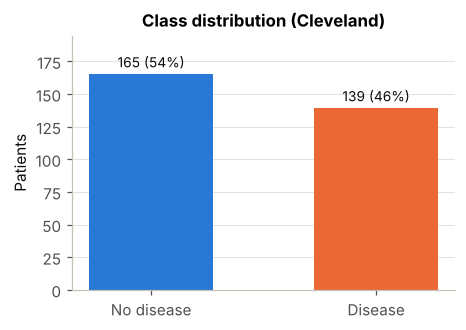

In [17]:
counts = cle["target_label"].value_counts().reindex(["No disease", "Disease"])
fig, ax = plt.subplots(figsize=(4.5, 3))
bars = ax.bar(counts.index, counts.values, color=[NO_DISEASE, DISEASE], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 3, f"{v} ({v / counts.sum():.0%})",
            ha="center", va="bottom", color=INK, fontsize=9)
ax.set_ylabel("Patients"); ax.set_ylim(0, counts.max() * 1.18)
ax.set_title("Class distribution (Cleveland)")
ax.grid(axis="x", visible=False)
save(fig, "fig2_class_balance")
plt.show()

### 3.2 Summary statistics by disease status

In [18]:
summary = cle.groupby("target_label", observed=True)[numeric].agg(["mean", "std"]).T.unstack()
summary = summary.reindex(columns=["No disease", "Disease"], level=0).round(1)
summary

target_label No disease       Disease      
                   mean   std    mean   std
age                52.4   9.7    56.6   7.9
trestbps          129.3  16.2   134.6  18.8
chol              242.0  54.0   251.5  49.5
thalch            158.5  19.3   139.3  22.6
oldpeak             0.6   0.8     1.6   1.3

### 3.3 Distributions of the continuous variables (histograms)

saved figures/fig3_histograms.png


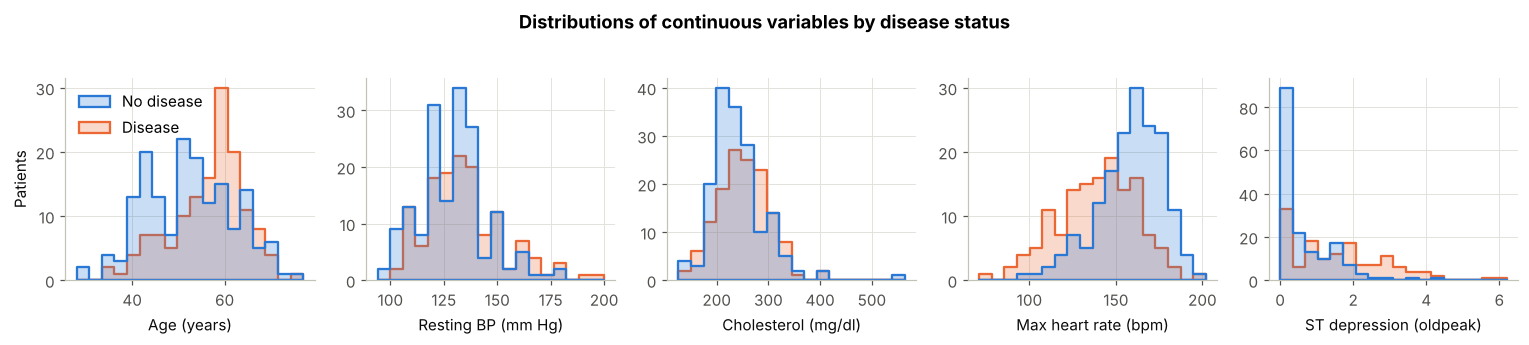

In [19]:
labels = {"age": "Age (years)", "trestbps": "Resting BP (mm Hg)", "chol": "Cholesterol (mg/dl)",
          "thalch": "Max heart rate (bpm)", "oldpeak": "ST depression (oldpeak)"}
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for ax, c in zip(axes, numeric):
    sns.histplot(data=cle, x=c, hue="target_label", hue_order=["No disease", "Disease"],
                 palette=TARGET_PALETTE, bins=18, element="step", fill=True, alpha=0.25,
                 linewidth=1.5, ax=ax, legend=(c == "age"))
    ax.set_xlabel(labels[c]); ax.set_ylabel("Patients" if c == "age" else "")
leg = axes[0].get_legend(); leg.set_title(None)
fig.suptitle("Distributions of continuous variables by disease status", fontweight="bold", y=1.03)
fig.tight_layout()
save(fig, "fig3_histograms")
plt.show()

### 3.4 Boxplots by disease status

saved figures/fig4_boxplots.png


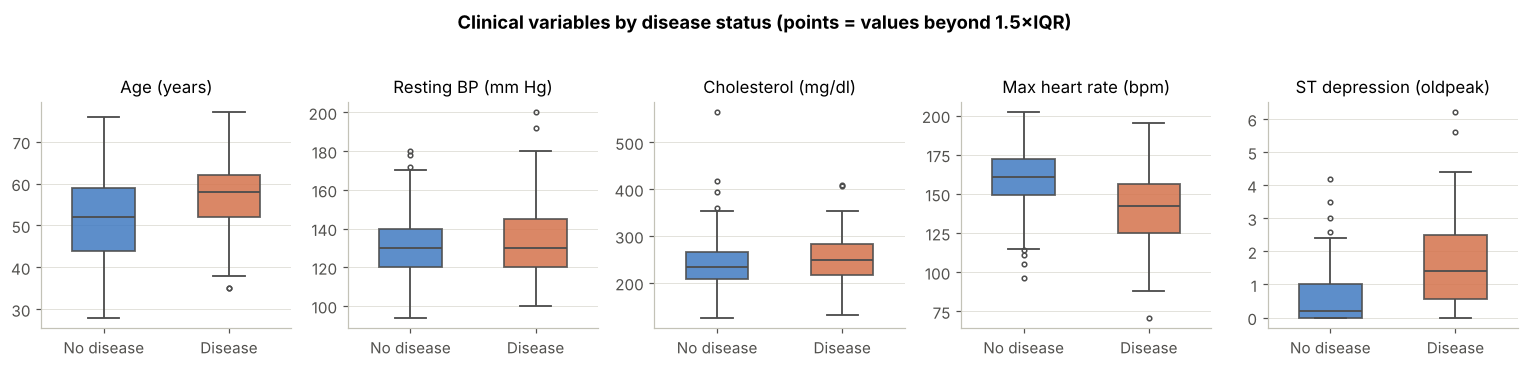

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2))
for ax, c in zip(axes, numeric):
    sns.boxplot(data=cle, x="target_label", y=c, hue="target_label", order=["No disease", "Disease"],
                palette=TARGET_PALETTE, width=0.5, linewidth=1.2, fliersize=3, ax=ax, legend=False,
                boxprops={"alpha": 0.85})
    ax.set_xlabel(""); ax.set_ylabel(""); ax.set_title(labels[c], fontweight="normal")
    ax.grid(axis="x", visible=False)
fig.suptitle("Clinical variables by disease status (points = values beyond 1.5×IQR)", fontweight="bold", y=1.03)
fig.tight_layout()
save(fig, "fig4_boxplots")
plt.show()

### 3.5 Correlation heatmap
Categorical variables are encoded numerically for this overview only: binary variables as 0/1, `cp` as
1 = asymptomatic (the chest pain type most associated with disease in prior studies), `thal` as 1 = reversible
defect, `slope` as 1 = flat or downsloping, and `restecg` as 1 = any abnormality. Pearson correlation with a
0/1 variable equals the point-biserial correlation.

saved figures/fig5_correlation_heatmap.png


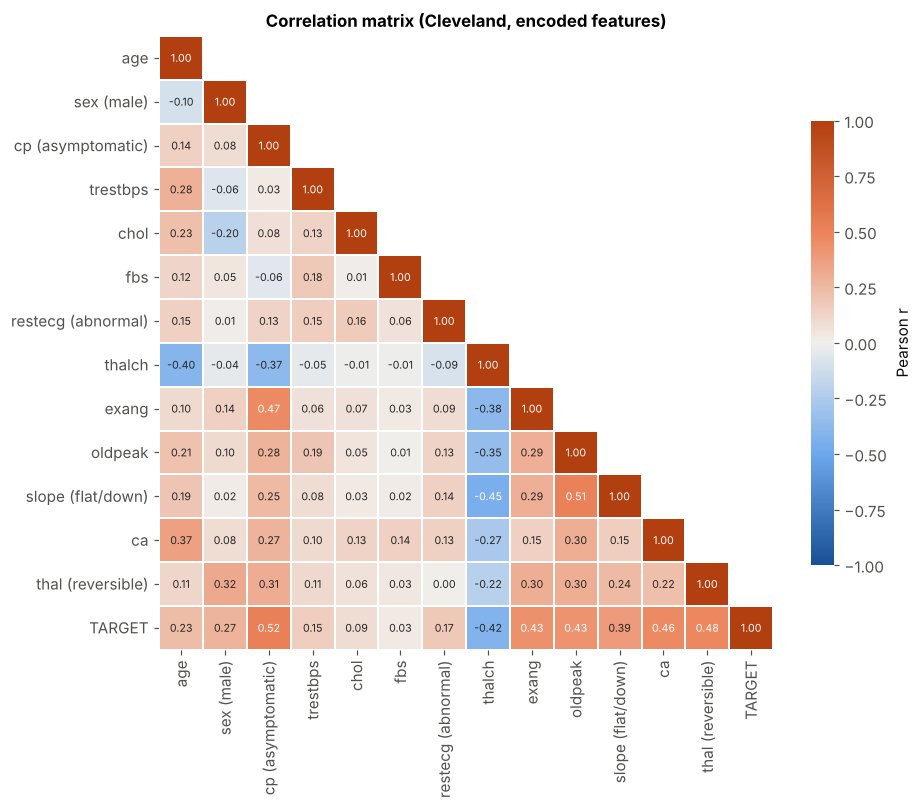

In [21]:
enc = pd.DataFrame({
    "age": cle["age"], "sex (male)": (cle["sex"] == "Male").astype(int),
    "cp (asymptomatic)": (cle["cp"] == "asymptomatic").astype(int),
    "trestbps": cle["trestbps"], "chol": cle["chol"], "fbs": cle["fbs"],
    "restecg (abnormal)": (cle["restecg"] != "normal").astype(int),
    "thalch": cle["thalch"], "exang": cle["exang"], "oldpeak": cle["oldpeak"],
    "slope (flat/down)": (cle["slope"] != "upsloping").astype(int),
    "ca": cle["ca"], "thal (reversible)": (cle["thal"] == "reversible defect").astype(int),
    "TARGET": cle["target"],
})
corr = enc.corr()
div = LinearSegmentedColormap.from_list("div", ["#184f95", "#6da7ec", "#f0efec", "#ec835a", "#b13f0f"])
fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=div, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=1, linecolor="white", square=True,
            cbar_kws={"label": "Pearson r", "shrink": 0.7}, ax=ax)
ax.set_title("Correlation matrix (Cleveland, encoded features)")
ax.grid(False)
save(fig, "fig5_correlation_heatmap")
plt.show()

In [22]:
target_corr = corr["TARGET"].drop("TARGET").sort_values(key=np.abs, ascending=False).round(3)
target_corr.to_frame("r with disease")

,r with disease
cp (asymptomatic),0.518
thal (reversible),0.482
ca,0.461
exang,0.433
oldpeak,0.426
thalch,-0.420
slope (flat/down),0.389
sex (male),0.274
age,0.228
restecg (abnormal),0.172


### 3.6 Disease prevalence by age group and sex

In [23]:
bins = [28, 40, 50, 60, 70, 80]
age_labels = ["29–40", "41–50", "51–60", "61–70", "71–77"]
cle["age_group"] = pd.cut(cle["age"], bins=bins, labels=age_labels)

prev = (cle.groupby(["age_group", "sex"], observed=True)["target"]
          .agg(["mean", "size"]).rename(columns={"mean": "prevalence", "size": "n"}).reset_index())
prev_table = prev.pivot(index="age_group", columns="sex", values=["n", "prevalence"])
display(prev_table.round(2))
print(cle.groupby("sex", observed=True)["target"].agg(["mean", "size"]).round(3))

n       prevalence      
sex       Female  Male     Female  Male
age_group                              
29–40        5.0  13.0       0.00  0.46
41–50       22.0  54.0       0.05  0.41
51–60       36.0  94.0       0.33  0.57
61–70       29.0  44.0       0.41  0.70
71–77        5.0   1.0       0.00  1.00

         mean  size
sex                
Female  0.258    97
Male    0.551   207


saved figures/fig6_prevalence_age_sex.png


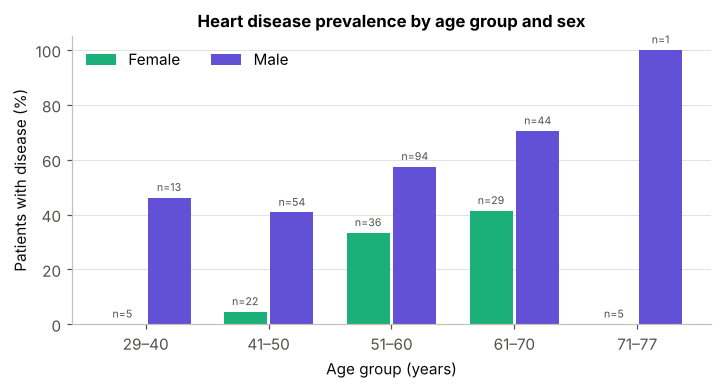

In [24]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(len(age_labels)); w = 0.38
for i, (sex, col) in enumerate([("Female", FEMALE), ("Male", MALE)]):
    sub = prev[prev["sex"] == sex].set_index("age_group").reindex(age_labels)
    bars = ax.bar(x + (i - 0.5) * w, sub["prevalence"] * 100, width=w - 0.03, color=col, label=sex)
    for b, (p, n) in zip(bars, zip(sub["prevalence"], sub["n"])):
        if pd.notna(p):
            ax.text(b.get_x() + b.get_width() / 2, p * 100 + 1.5, f"n={int(n)}",
                    ha="center", va="bottom", fontsize=7, color=MUTED)
ax.set_xticks(x, age_labels); ax.set_xlabel("Age group (years)")
ax.set_ylabel("Patients with disease (%)"); ax.set_ylim(0, 105)
ax.legend(loc="upper left", ncols=2)
ax.set_title("Heart disease prevalence by age group and sex")
ax.grid(axis="x", visible=False)
save(fig, "fig6_prevalence_age_sex")
plt.show()

### 3.7 Disease prevalence across categorical features

saved figures/fig7_prevalence_categorical.png


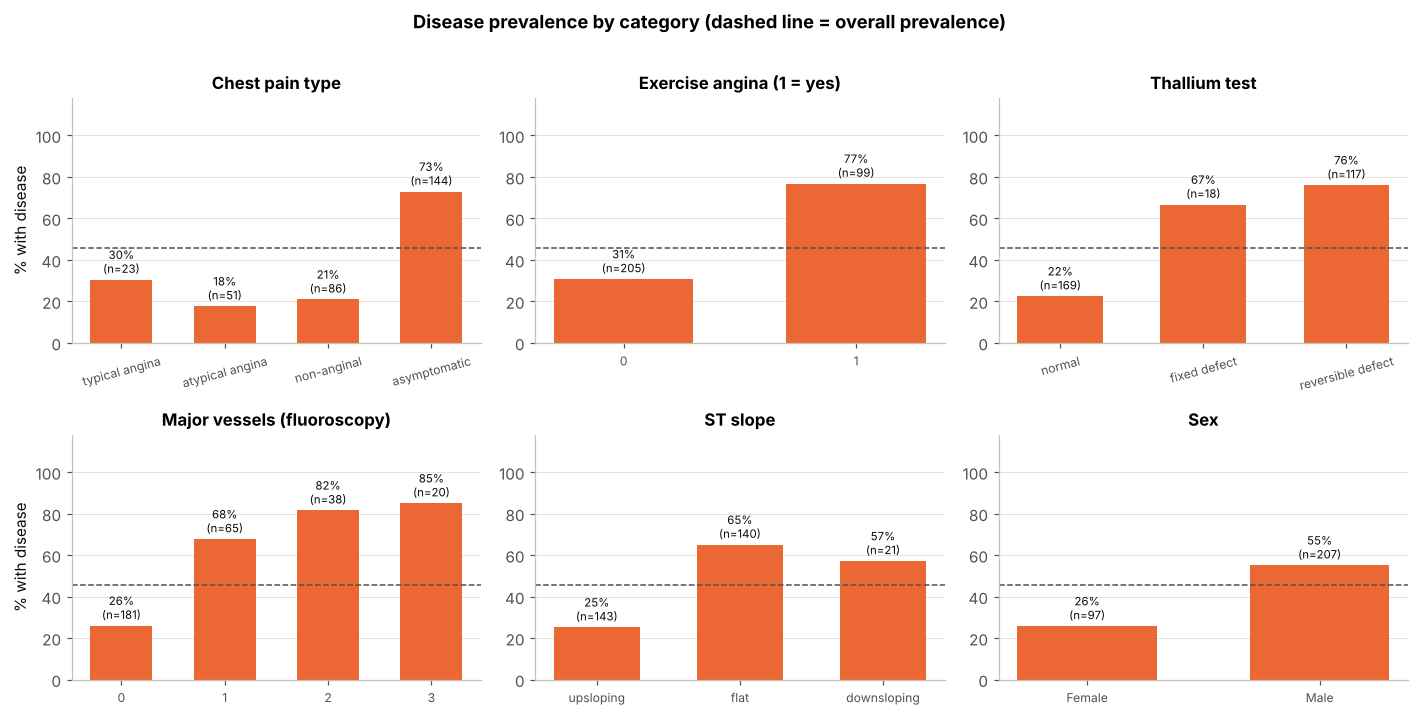

In [25]:
cat_feats = {"cp": "Chest pain type", "exang": "Exercise angina (1 = yes)", "thal": "Thallium test",
             "ca": "Major vessels (fluoroscopy)", "slope": "ST slope", "sex": "Sex"}
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4))
for ax, (c, title) in zip(axes.ravel(), cat_feats.items()):
    g = cle.groupby(c, observed=True)["target"].agg(["mean", "size"])
    bars = ax.bar(g.index.astype(str), g["mean"] * 100, color=DISEASE, width=0.6)
    for b, (p, n) in zip(bars, zip(g["mean"], g["size"])):
        ax.text(b.get_x() + b.get_width() / 2, p * 100 + 2, f"{p:.0%}\n(n={n})",
                ha="center", va="bottom", fontsize=7.5, color=INK)
    ax.axhline(cle["target"].mean() * 100, color=MUTED, lw=1, ls="--")
    ax.set_ylim(0, 118); ax.set_title(title); ax.set_ylabel("% with disease" if c in ("cp", "ca") else "")
    ax.tick_params(axis="x", labelsize=8, rotation=15 if c in ("cp", "thal") else 0)
    ax.grid(axis="x", visible=False)
fig.suptitle("Disease prevalence by category (dashed line = overall prevalence)", fontweight="bold", y=1.01)
fig.tight_layout()
save(fig, "fig7_prevalence_categorical")
plt.show()

In [26]:
# The same information as a table
cat_prev = pd.concat({c: cle.groupby(c, observed=True)["target"].agg(prevalence="mean", n="size")
                      for c in cat_feats}, names=["feature", "level"]).round(3)
cat_prev

prevalence    n
feature level                             
cp      typical angina          0.304   23
        atypical angina         0.176   51
        non-anginal             0.209   86
        asymptomatic            0.729  144
exang   0                       0.307  205
        1                       0.768   99
thal    normal                  0.225  169
        fixed defect            0.667   18
        reversible defect       0.761  117
ca      0                       0.260  181
        1                       0.677   65
        2                       0.816   38
        3                       0.850   20
slope   upsloping               0.252  143
        flat                    0.650  140
        downsloping             0.571   21
sex     Female                  0.258   97
        Male                    0.551  207

### 3.8 Scatter plot: age vs maximum heart rate

saved figures/fig8_scatter_age_thalch.png


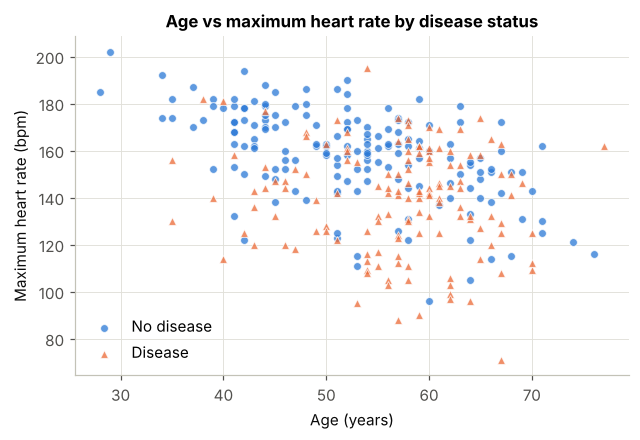

r(age, thalch) = -0.402


In [27]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for lab, col, mk in [("No disease", NO_DISEASE, "o"), ("Disease", DISEASE, "^")]:
    s = cle[cle["target_label"] == lab]
    ax.scatter(s["age"], s["thalch"], s=26, color=col, marker=mk, alpha=0.75,
               edgecolor="white", linewidth=0.6, label=lab)
ax.set_xlabel("Age (years)"); ax.set_ylabel("Maximum heart rate (bpm)")
ax.legend(loc="lower left")
ax.set_title("Age vs maximum heart rate by disease status")
save(fig, "fig8_scatter_age_thalch")
plt.show()
print("r(age, thalch) =", round(cle["age"].corr(cle["thalch"]), 3))

## 4. Key observations so far

The numbers below are printed from the data so the written summary can be checked against them.

In [28]:
def pct(mask): return f"{cle.loc[mask, 'target'].mean():.0%}"
obs = {
    "patients": len(cle),
    "disease_n": int(cle["target"].sum()),
    "prevalence": f"{cle['target'].mean():.1%}",
    "male_share": f"{(cle['sex'] == 'Male').mean():.0%}",
    "prev_male": pct(cle["sex"] == "Male"), "prev_female": pct(cle["sex"] == "Female"),
    "prev_asymptomatic_cp": pct(cle["cp"] == "asymptomatic"),
    "prev_other_cp": pct(cle["cp"] != "asymptomatic"),
    "prev_exang_yes": pct(cle["exang"] == 1), "prev_exang_no": pct(cle["exang"] == 0),
    "prev_thal_reversible": pct(cle["thal"] == "reversible defect"),
    "prev_thal_normal": pct(cle["thal"] == "normal"),
    "prev_ca0": pct(cle["ca"] == 0), "prev_ca_ge1": pct(cle["ca"] >= 1),
    "thalch_mean_no": round(cle.loc[cle.target == 0, "thalch"].mean(), 1),
    "thalch_mean_yes": round(cle.loc[cle.target == 1, "thalch"].mean(), 1),
    "oldpeak_mean_no": round(cle.loc[cle.target == 0, "oldpeak"].mean(), 2),
    "oldpeak_mean_yes": round(cle.loc[cle.target == 1, "oldpeak"].mean(), 2),
    "chol_mean_no": round(cle.loc[cle.target == 0, "chol"].mean(), 1),
    "chol_mean_yes": round(cle.loc[cle.target == 1, "chol"].mean(), 1),
    "top5_corr": target_corr.head(5).to_dict(),
}
for k, v in obs.items():
    print(f"{k:>22}: {v}")

              patients: 304
             disease_n: 139
            prevalence: 45.7%
            male_share: 68%
             prev_male: 55%
           prev_female: 26%
  prev_asymptomatic_cp: 73%
         prev_other_cp: 21%
        prev_exang_yes: 77%
         prev_exang_no: 31%
  prev_thal_reversible: 76%
      prev_thal_normal: 22%
              prev_ca0: 26%
           prev_ca_ge1: 75%
        thalch_mean_no: 158.5
       thalch_mean_yes: 139.3
       oldpeak_mean_no: 0.58
      oldpeak_mean_yes: 1.57
          chol_mean_no: 242.0
         chol_mean_yes: 251.5
             top5_corr: {'cp (asymptomatic)': 0.518, 'thal (reversible)': 0.482, 'ca': 0.461, 'exang': 0.433, 'oldpeak': 0.426}


**Summary**

* **Class balance:** roughly balanced (about 54% no disease vs 46% disease), so accuracy will be a meaningful
  metric, though precision, recall and F1 will also be reported.
* **Strongest visual signals:** asymptomatic chest pain, exercise-induced angina, a reversible thallium defect,
  one or more vessels coloured by fluoroscopy, higher ST depression and lower maximum heart rate are all
  clearly more common among patients with disease. This matches the hypothesis in the proposal.
* **Weak signals:** cholesterol, resting blood pressure and fasting blood sugar differ little between groups.
* **Age and sex:** prevalence rises with age, and men have a much higher prevalence than women in this sample.
  Women are only about a third of the patients, so the female estimates (especially in the youngest and oldest
  age groups) rest on small numbers.
* **Potential biases:** the patients were referred for angiography, so this is not a general-population sample;
  men are over-represented; and the data come from one hospital in the 1980s.

**Next steps:** Welch t-tests (with Mann–Whitney checks) and chi-square tests with effect sizes and multiple-test
correction, then logistic regression with an 80/20 stratified split, compared against a majority-class baseline
and a tree-based model.